In [1]:
from src.motivating_example import MotivatingExample
import numpy as np
from scipy.stats import norm

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

In [59]:
from src.gaussian_mixture import GaussianMixtureMAR
import torch

In [ ]:
me = MotivatingExample()
X = me.get_X()
M = me.get_M(X)
# Phat(M=(0,0))
pmhat = (M==1).all(dim=1).sum()/me.n
X_M0 = X[(M==1).all(dim=1)]

g1 = GaussianMixtureMAR(k_range=(0,10))
g1.fit(X_M0, torch.ones_like(X_M0))
# phat(xm0)
logpxm0 = g1.log_prob_x(X_M0)

g2 = GaussianMixtureMAR(k_range=(0,10))
g2.fit(X, M)
# phat(x)
logpx = g2.log_prob_x(X)[(M==1).all(dim=1)]


$$
\mathbb P(M=0 \mid X=x) = \frac{p (X=x \mid M=0) \mathbb P(M=0)}{p(x)}
$$

In [102]:
pme = (logpxm0 - logpx).exp() * pmhat

In [2]:
# import pickle
# with open("motexp.pkl", "rb") as f:
#     res = pickle.load(f)

In [3]:
B = 50

res = {
    'mar': np.empty((B, 8)),
    'mar_like': np.empty((B, 8)),
    'mnar': np.empty((10, B, 8))
}

types = ['mar', 'mar_like', 'mnar']

for m in types:
    me = MotivatingExample(type=m, n=2000, d=2, B=B)
    res[m] = me.evaluate()

In [4]:
qs = {
    'mar': res['mar'][['qx1_gen', 'qx1_imp']],
    'mar_like': res['mar_like'][['qx1_gen', 'qx1_imp']],
    'mnar': res['mnar'][:,:,0].T
}

ticklabels = {
    'mar': ["Generation", "Imputation"],
    'mar_like': ["Generation", "Imputation"],
    'mnar': [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
}

subtitles = {
    'mar': 'MAR',
    'mar_like': 'MAR-like MNAR',
    'mnar': r'MAR with $\epsilon$-contamination of MNAR'
}

xlabels = {
    'mar': 'Method',
    'mar_like': 'Method',
    'mnar': r'$\epsilon$'
}

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


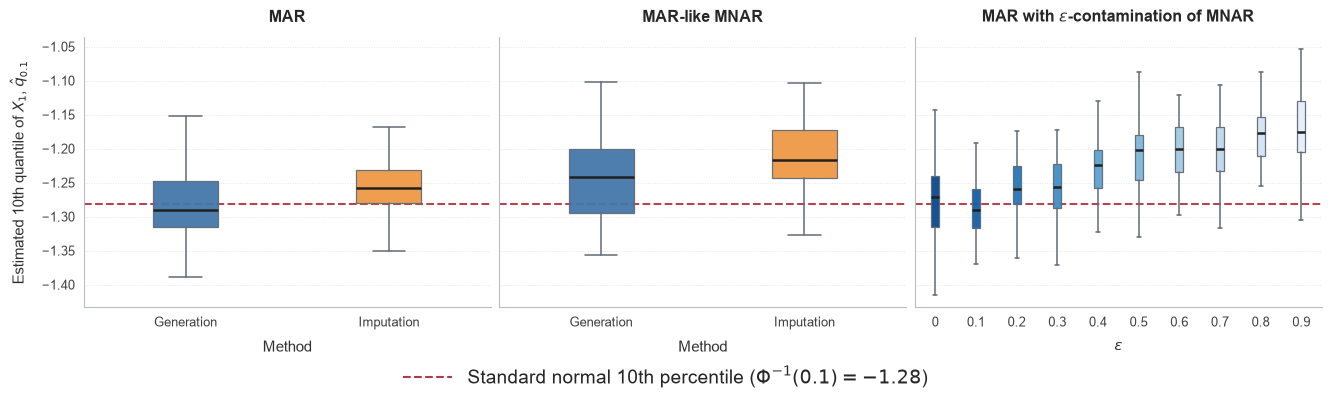

In [5]:
# --------------------------------------------------
# Global style
# --------------------------------------------------
sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.15,
    rc={
        "font.family": "sans-serif",
        "axes.titleweight": "semibold",
        "axes.labelcolor": "#303030",
        "xtick.color": "#404040",
        "ytick.color": "#404040",
        "grid.color": "#D9DEE7",
        "grid.linewidth": 0.65,
        "axes.edgecolor": "#B8BEC8",
        "axes.linewidth": 0.8,
        "savefig.dpi": 300,
    },
)

# --------------------------------------------------
# Figure setup
# --------------------------------------------------
n_types = len(types)

if n_types == 0:
    raise ValueError("types must contain at least one panel.")

fig, axes = plt.subplots(
    1,
    n_types,
    figsize=(4.4 * n_types, 4.0),
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

# Theoretical 10th percentile of the standard normal
q10 = norm.ppf(0.1)

# Colors
two_box_colors = ["#4477AA", "#EE9944"]
reference_color = "#B23A48"

# Ten shades from dark blue to light blue
blue_gradient = sns.color_palette(
    "Blues", n_colors=10
)[::-1]

# --------------------------------------------------
# Draw panels
# --------------------------------------------------
for ax, type_name in zip(axes, types):

    data = qs[type_name]

    # Number of boxplots
    n_boxes = data.shape[1] if data.ndim > 1 else 1

    # Adaptive width: narrow for two boxes, suitable for ten
    box_width = min(0.32, 2.0 / n_boxes)

    bp = ax.boxplot(
        data,
        tick_labels=ticklabels[type_name],
        patch_artist=True,
        widths=box_width,
        showfliers=False,
        medianprops=dict(
            color="#202020",
            linewidth=1.8,
        ),
        whiskerprops=dict(
            color="#626B75",
            linewidth=1.1,
        ),
        capprops=dict(
            color="#626B75",
            linewidth=1.1,
        ),
        boxprops=dict(
            edgecolor="#626B75",
            linewidth=0.9,
        ),
        zorder=2,
    )

    # Choose palette based on number of boxes
    if n_boxes == 2:
        colors = two_box_colors
    elif n_boxes == 10:
        colors = blue_gradient
    else:
        colors = sns.color_palette(
            "Blues", n_colors=n_boxes + 2
        )[1:-1]

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Theoretical reference line
    ax.axhline(
        q10,
        color=reference_color,
        linestyle="--",
        linewidth=1.5,
        alpha=0.95,
        zorder=1,
    )

    # Titles and labels
    ax.set_title(
        subtitles[type_name],
        fontsize=11.5,
        pad=11,
        fontweight="semibold",
    )

    ax.set_xlabel(
        xlabels[type_name],
        fontsize=10.5,
        labelpad=8,
    )

    # Grid and spines
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle=":", alpha=0.8)
    ax.grid(axis="x", visible=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=9,
        length=3,
        color="#8A9099",
    )

    # Add whitespace around the boxes
    ax.margins(x=0.12)

# --------------------------------------------------
# Shared y-axis label
# --------------------------------------------------
axes[0].set_ylabel(
    r"Estimated 10th quantile of $X_1$, $\hat{q}_{0.1}$",
    fontsize=10.5,
    labelpad=10,
)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------
reference_handle = Line2D(
    [0],
    [0],
    color=reference_color,
    linestyle="--",
    linewidth=1.5,
    label=fr"Standard normal 10th percentile ($\Phi^{{-1}}(0.1)={q10:.2f}$)",
)

fig.legend(
    handles=[reference_handle],
    loc="outside lower center",
    frameon=False,
    fontsize=14,
    handlelength=2.5,
)

# --------------------------------------------------
# Save figures
# --------------------------------------------------
fig.savefig(
    "motexp.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    "motexp.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


In [21]:
me = MotivatingExample()

In [29]:
qxs = []

for _ in range(500):
    X = me.get_X()
    M = me.get_M(X)
    XM0 = X[(M==1).all(dim=1)]
    qxs.append(np.quantile(XM0[:,0], 0.1))

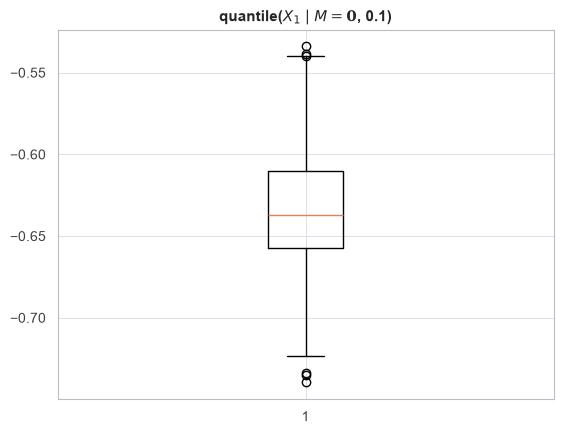

In [30]:
plt.boxplot(qxs)
plt.title(r'quantile($X_1\mid M=\mathbf{0}$, 0.1)')
plt.show()

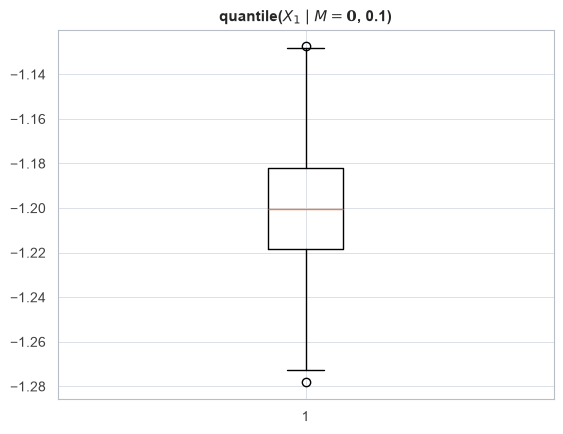

In [34]:
qxs = []

for _ in range(500):
    X = me.get_X()
    M = me.get_M(X)
    XM0 = X[M[:, 0]==1]
    qxs.append(np.quantile(XM0[:,0], 0.1))

plt.boxplot(qxs)
plt.title(r'quantile($X_1\mid M=\mathbf{0}$, 0.1)')
plt.show()

In [111]:
X1p= X_M0[:, 0]
X2p = X_M0[:, 1]

norm = torch.distributions.Normal(0., 1.)
Z = (norm.cdf(X1p) + norm.cdf(X2p)) / 3
Zhat = pme.flatten()

In [ ]:
from matplotlib.colors import TwoSlopeNorm

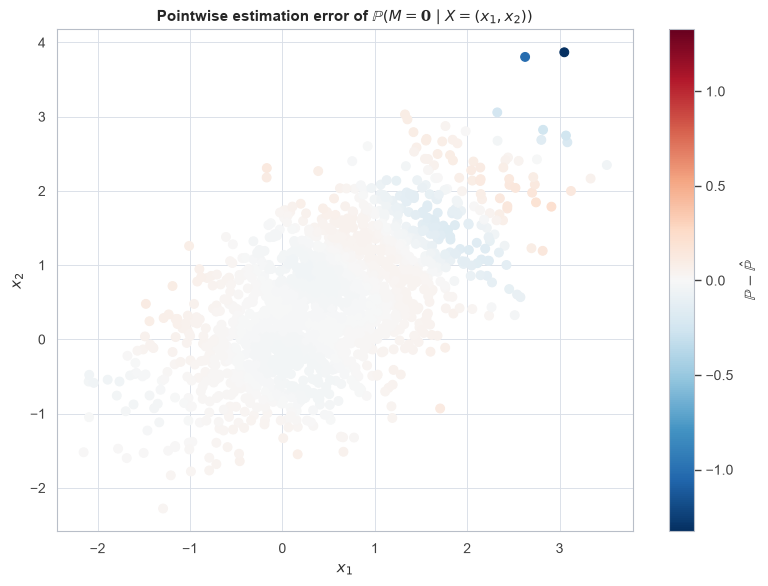

In [112]:
error = (Z - Zhat).detach().cpu().numpy()
limit = max(np.max(np.abs(error)), 1e-12)

fig, ax = plt.subplots(figsize=(8, 6))


sc = ax.scatter(
    X1p.detach().cpu().numpy() if isinstance(X1p, torch.Tensor) else X1p,
    X2p.detach().cpu().numpy() if isinstance(X2p, torch.Tensor) else X2p,
    c=error,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    s=40
)

fig.colorbar(sc, ax=ax, label=r"$\mathbb{P}-\hat \mathbb{P}$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
plt.tight_layout()
plt.show()

<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\hu\AppData\Local\Temp\ipykernel_28512\1307428141.py:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax.set_zlabel("$\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")


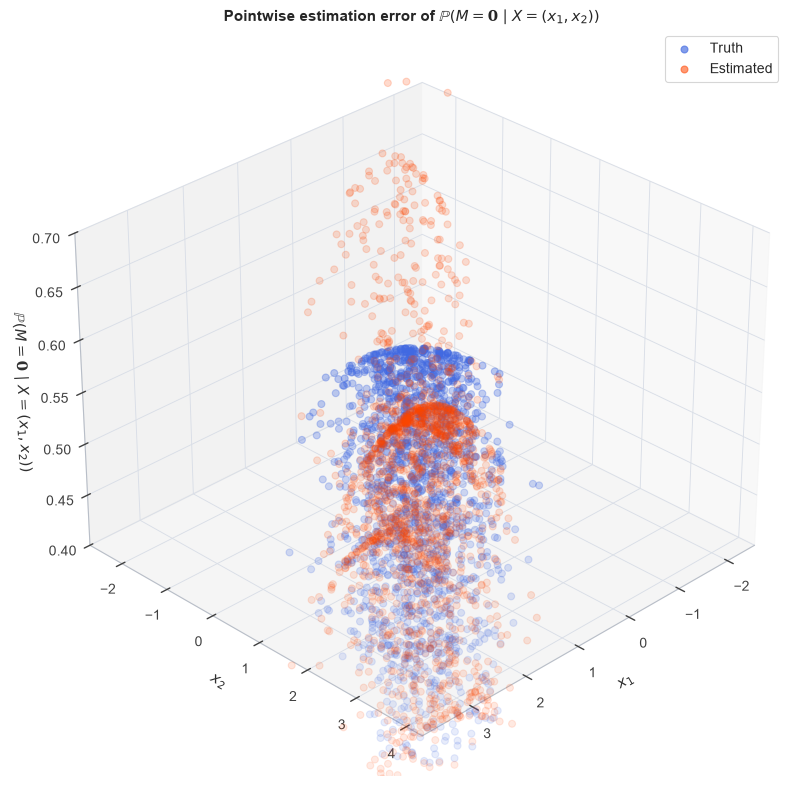

In [119]:
Z_np = Z.detach().cpu().numpy() if hasattr(Z, "detach") else np.asarray(Z)
Zp_np = Zhat.detach().cpu().numpy() if hasattr(pme, "detach") else np.asarray(pme)

Z_np = Z_np.reshape(-1)
Zp_np = Zp_np.reshape(-1)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# Reference function
ax.scatter(
    X1p, X2p, Z_np,
    color="royalblue", alpha=0.65,
    s=25, label=r"Truth"
)

# Estimated function
ax.scatter(
    X1p, X2p, Zp_np,
    color="orangered", alpha=0.55,
    s=25, label=r"Estimated"
)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
ax.set_title(r"Pointwise estimation error of $\mathbb{P}(M=\mathbf{0} \mid X=(x_1,x_2))$")
ax.legend()
ax.set_zlim(0.4, 0.7)
ax.view_init(elev=30, azim=45)
plt.tight_layout()
plt.show()


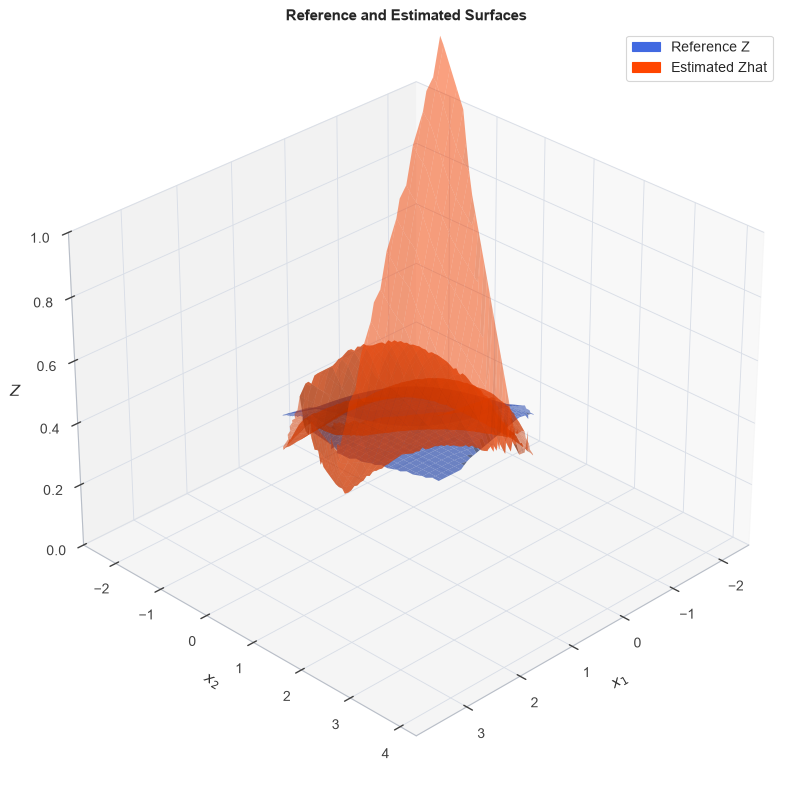

In [120]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# Convert to NumPy vectors
x1 = X_M0[:, 0].detach().cpu().numpy()
x2 = X_M0[:, 1].detach().cpu().numpy()

z = Z.detach().cpu().numpy().reshape(-1)
zhat = Zhat.detach().cpu().numpy().reshape(-1)

# Create a regular grid
xi = np.linspace(x1.min(), x1.max(), 100)
yi = np.linspace(x2.min(), x2.max(), 100)
X1, X2 = np.meshgrid(xi, yi)

# Interpolate scattered points onto the grid
Z_grid = griddata((x1, x2), z, (X1, X2), method="linear")
Zhat_grid = griddata((x1, x2), zhat, (X1, X2), method="linear")

# Plot both surfaces
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X1, X2, Z_grid,
    color="royalblue", alpha=0.7,
    edgecolor="none", label="Reference Z"
)
ax.plot_surface(
    X1, X2, Zhat_grid,
    color="orangered", alpha=0.5,
    edgecolor="none"
)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$Z$")
ax.set_zlim(0, 1)
ax.set_title("Reference and Estimated Surfaces")
ax.view_init(elev=30, azim=45)

# Legend proxies
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="royalblue", label="Reference Z"),
    Patch(color="orangered", label="Estimated Zhat")
])

plt.tight_layout()
plt.show()
